# 06 — OpenCV Thresholding & Segmentation

This notebook covers binary thresholding, adaptive thresholding, Otsu's method, masks, and basic segmentation workflows.

**Goal:** turn image intensity/color information into regions that can be separated and processed independently.

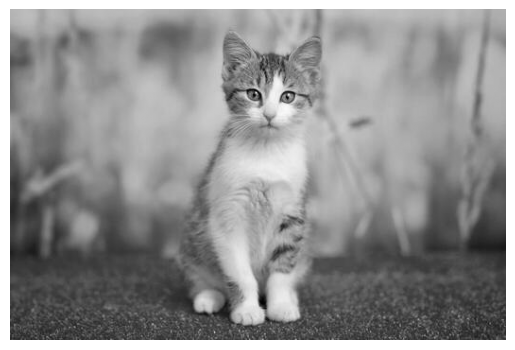

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cat.jpg")

if image is None:
    raise FileNotFoundError("cat.jpg not found")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

## 1. What is thresholding?

Thresholding converts continuous intensity values into discrete regions.

For a simple binary threshold:

\[
T(x,y)=
\begin{cases}
255 & I(x,y)>T \\
0 & I(x,y)\leq T
\end{cases}
\]

## 2. `cv2.threshold()`

**Syntax:** `retval, dst = cv2.threshold(src, thresh, maxval, type)`

- `thresh` → threshold value
- `maxval` → value assigned to selected pixels
- `type` → thresholding method
- **Return:** threshold used and output image

Threshold used: 127.0


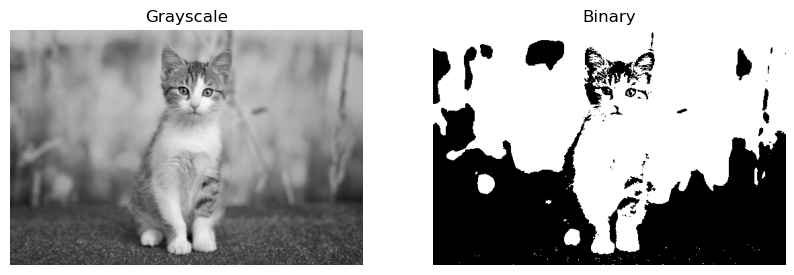

In [21]:
threshold_value = 127

ret, binary = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

print("Threshold used:", ret)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Grayscale")
axes[1].imshow(binary, cmap="gray")
axes[1].set_title("Binary")
for ax in axes:
    ax.axis("off")
plt.show()

## 3. Main threshold types

OpenCV provides several basic modes:

- `THRESH_BINARY`
- `THRESH_BINARY_INV`
- `THRESH_TRUNC`
- `THRESH_TOZERO`
- `THRESH_TOZERO_INV`

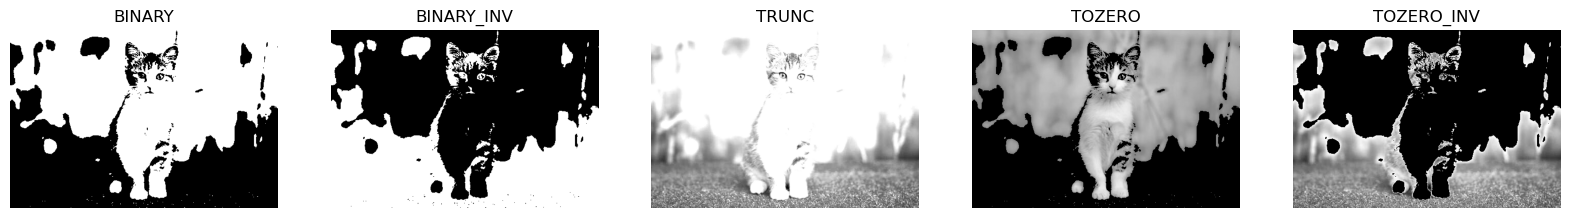

In [4]:
types = {
    "BINARY": cv2.THRESH_BINARY,
    "BINARY_INV": cv2.THRESH_BINARY_INV,
    "TRUNC": cv2.THRESH_TRUNC,
    "TOZERO": cv2.THRESH_TOZERO,
    "TOZERO_INV": cv2.THRESH_TOZERO_INV
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (name, mode) in zip(axes, types.items()):
    _, result = cv2.threshold(gray, 127, 255, mode)
    ax.imshow(result, cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.show()


## 4. Binary vs Binary Inverse

`THRESH_BINARY` makes pixels above the threshold white.

`THRESH_BINARY_INV` does the opposite, which is useful when the object/background polarity is reversed.

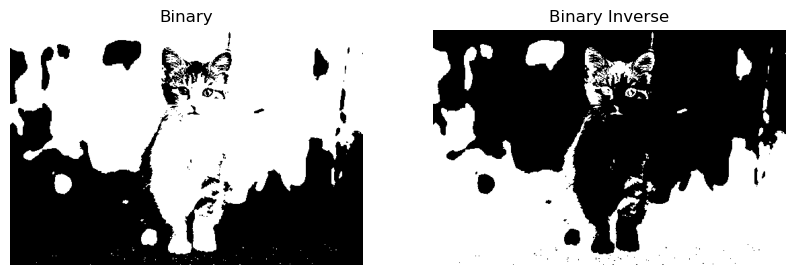

In [5]:
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
_, binary_inv = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(binary, cmap="gray")
axes[0].set_title("Binary")
axes[1].imshow(binary_inv, cmap="gray")
axes[1].set_title("Binary Inverse")
for ax in axes:
    ax.axis("off")
plt.show()


## 5. Threshold value and output

Changing `T` changes which pixels belong to the foreground.

A low threshold selects more pixels; a high threshold selects fewer.

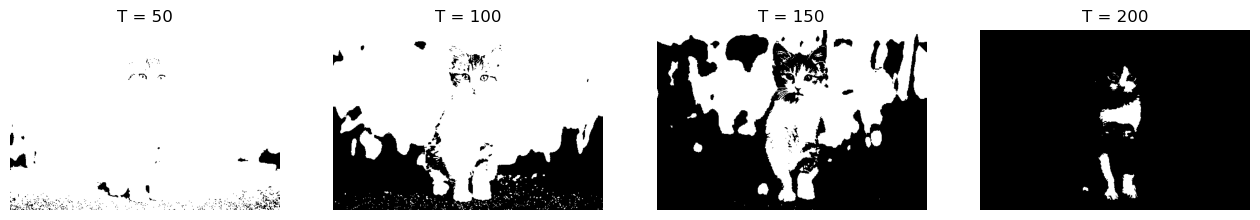

In [6]:
thresholds = [50, 100, 150, 200]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, t in zip(axes, thresholds):
    _, result = cv2.threshold(gray, t, 255, cv2.THRESH_BINARY)
    ax.imshow(result, cmap="gray")
    ax.set_title(f"T = {t}")
    ax.axis("off")

plt.show()


## 6. Otsu's thresholding

Otsu automatically chooses a threshold from the image histogram.

Use:

`cv2.THRESH_BINARY + cv2.THRESH_OTSU`

You normally pass `0` as the threshold because Otsu determines it for you.

Otsu threshold: 122.0


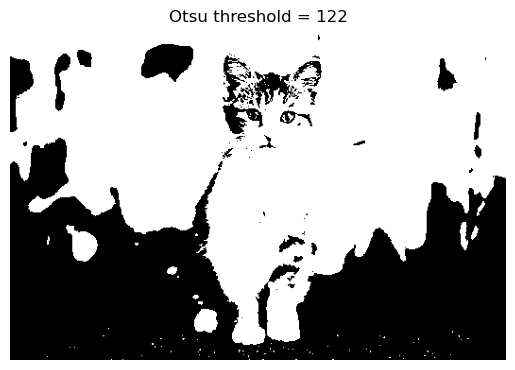

In [7]:
otsu_t, otsu = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu threshold:", otsu_t)

plt.imshow(otsu, cmap="gray")
plt.title(f"Otsu threshold = {otsu_t:.0f}")
plt.axis("off")
plt.show()


## 7. Otsu's Method — The Math

Otsu tries to find a threshold that gives the best separation between two intensity classes.

For foreground/background classes, it maximizes **between-class variance**:

$$
\sigma_B^2 = \omega_0\omega_1(\mu_0-\mu_1)^2
$$

where:

- $\omega_0, \omega_1$ are the class probabilities
- $\mu_0, \mu_1$ are the class means

The threshold producing the maximum between-class variance is selected.

```python
hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()

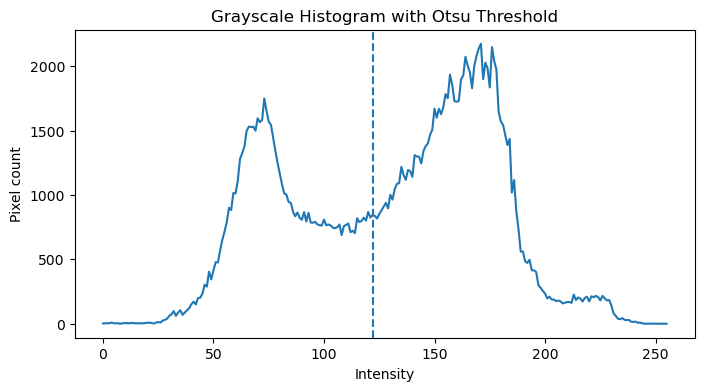

In [8]:
hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()

plt.figure(figsize=(8, 4))
plt.plot(hist)
plt.axvline(otsu_t, linestyle="--")
plt.title("Grayscale Histogram with Otsu Threshold")
plt.xlabel("Intensity")
plt.ylabel("Pixel count")
plt.show()


## 8. Adaptive thresholding

A single global threshold can fail when illumination changes across an image.

Adaptive thresholding calculates a threshold from a **local neighborhood**.

### Methods

- `ADAPTIVE_THRESH_MEAN_C` → neighborhood mean minus `C`
- `ADAPTIVE_THRESH_GAUSSIAN_C` → Gaussian-weighted neighborhood minus `C`

**Syntax:** `cv2.adaptiveThreshold(src, maxValue, adaptiveMethod, thresholdType, blockSize, C)`

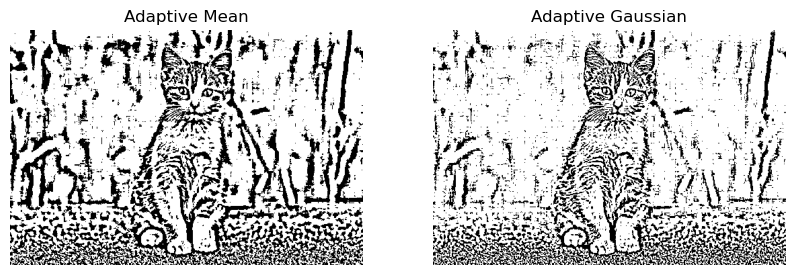

In [9]:
adaptive_mean = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

adaptive_gaussian = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(adaptive_mean, cmap="gray")
axes[0].set_title("Adaptive Mean")
axes[1].imshow(adaptive_gaussian, cmap="gray")
axes[1].set_title("Adaptive Gaussian")
for ax in axes:
    ax.axis("off")
plt.show()


## 9. Adaptive threshold parameters

`blockSize` defines the local neighborhood and must be an odd number greater than `1`.

`C` is subtracted from the calculated local threshold; changing it changes how much foreground is selected.

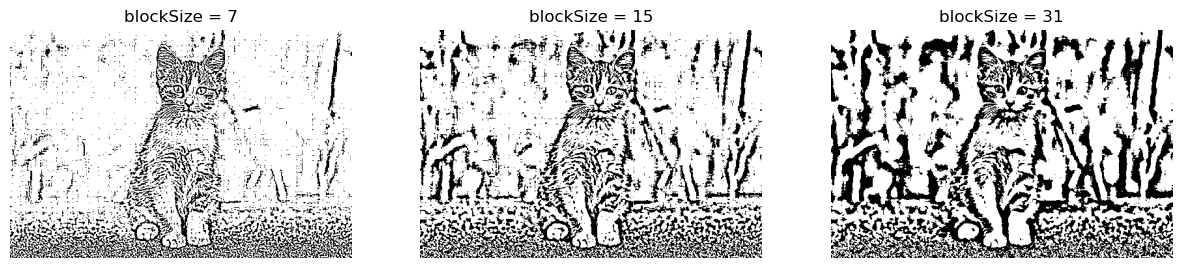

In [10]:
results = []

for block_size in [7, 15, 31]:
    result = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        block_size,
        2
    )
    results.append((block_size, result))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (block_size, result) in zip(axes, results):
    ax.imshow(result, cmap="gray")
    ax.set_title(f"blockSize = {block_size}")
    ax.axis("off")

plt.show()


## 10. Thresholding after smoothing

Noise can create unwanted foreground pixels.

A common pipeline is:

**grayscale → blur → threshold**

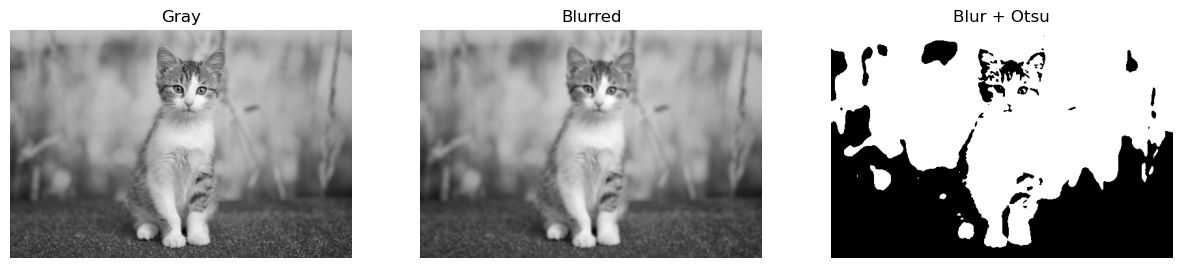

In [11]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

_, clean_binary = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Gray")
axes[1].imshow(blurred, cmap="gray")
axes[1].set_title("Blurred")
axes[2].imshow(clean_binary, cmap="gray")
axes[2].set_title("Blur + Otsu")
for ax in axes:
    ax.axis("off")
plt.show()


## 11. Segmentation

Segmentation means separating an image into meaningful regions.

Thresholding is one simple segmentation technique; color masks and later contour/morphology operations can build more complete pipelines.

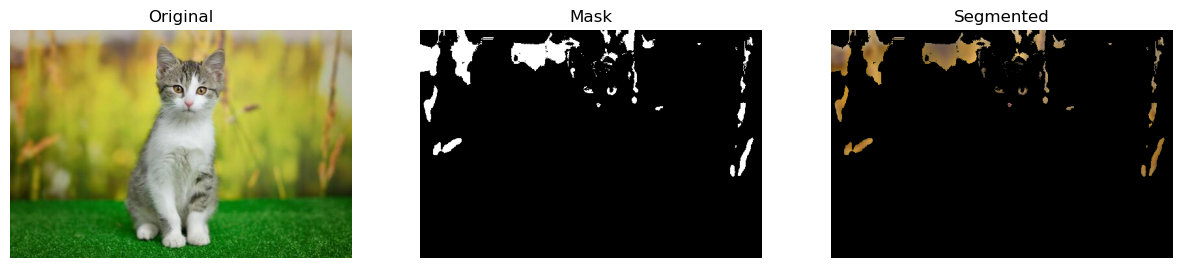

In [ ]:
# Example: HSV segmentation pipeline
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

lower = np.array([0, 70, 50])
upper = np.array([20, 255, 255])

mask = cv2.inRange(hsv, lower, upper)

segmented = cv2.bitwise_and(image, image, mask=mask)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Mask")
axes[2].imshow(cv2.cvtColor(segmented, cv2.COLOR_BGR2RGB))
axes[2].set_title("Segmented")
for ax in axes:
    ax.axis("off")
plt.show()

## 12. Binary masks as NumPy arrays

A binary mask is simply an image containing values such as `0` and `255`.

You can use Boolean indexing to inspect or modify the selected region.

In [13]:
foreground_pixels = np.count_nonzero(mask)
total_pixels = mask.size

print("Foreground pixels:", foreground_pixels)
print("Foreground percentage:",
      100 * foreground_pixels / total_pixels)


Foreground pixels: 9713
Foreground percentage: 5.285986394557823


## 13. Manual NumPy thresholding

Thresholding does not require OpenCV; NumPy can express the same operation directly.

This is useful for understanding what `cv2.threshold()` is doing conceptually.

In [14]:
manual = np.where(gray > 127, 255, 0).astype(np.uint8)

print("Difference from OpenCV:",
      np.count_nonzero(manual != binary))


Difference from OpenCV: 0


## 14. Multi-level thresholding

Binary thresholding creates two regions.

You can also define multiple intensity ranges to create more than two classes.

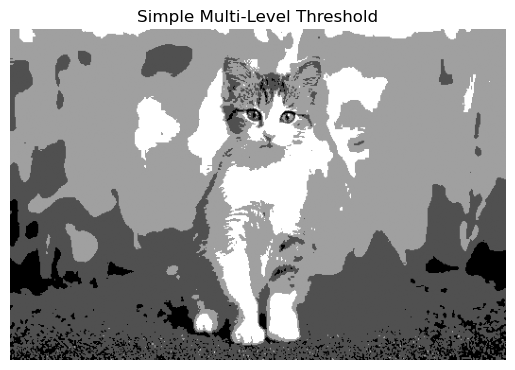

In [15]:
multi = np.zeros_like(gray)

multi[(gray >= 60) & (gray < 120)] = 80
multi[(gray >= 120) & (gray < 180)] = 160
multi[gray >= 180] = 255

plt.imshow(multi, cmap="gray")
plt.title("Simple Multi-Level Threshold")
plt.axis("off")
plt.show()


## 15. Choosing a thresholding method

| Situation | Good starting method |
|---|---|
| Known clean intensity separation | Global threshold |
| Uneven illumination | Adaptive threshold |
| Two well-separated histogram groups | Otsu |
| Color-based object selection | HSV + `inRange()` |
| Noisy image | Blur → threshold |

No single thresholding method works best for every image.

## 16. Important function cheat sheet

| Function | Purpose |
|---|---|
| `cv2.threshold()` | Global threshold |
| `cv2.adaptiveThreshold()` | Local/adaptive threshold |
| `cv2.inRange()` | Range-based mask |
| `cv2.bitwise_and()` | Apply mask |
| `cv2.calcHist()` | Histogram |
| `cv2.GaussianBlur()` | Reduce noise before thresholding |